In [40]:
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx

print("All imports successful!")
print("NumPy:", np.__version__)
print("NetworkX:", nx.__version__)

All imports successful!
NumPy: 2.5.5
NetworkX: 3.7


Nodes: 34
Edges: 78


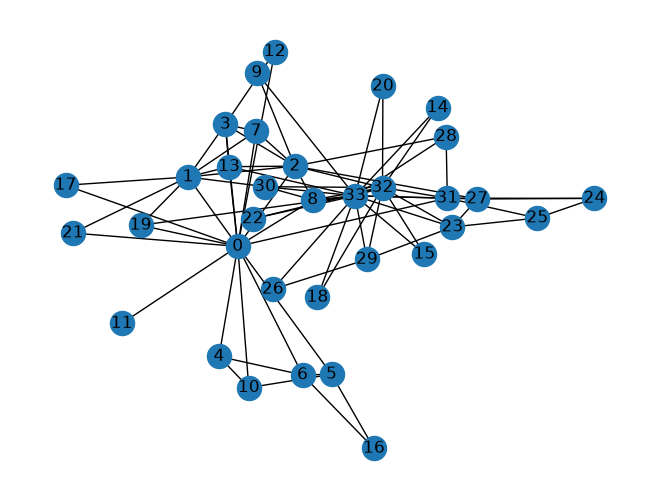

In [41]:
import networkx as nx
import matplotlib.pyplot as plt

G = nx.karate_club_graph()

print("Nodes:", G.number_of_nodes())
print("Edges:", G.number_of_edges())

nx.draw(G, with_labels=True)
plt.show()

In [42]:
import networkx as nx
import numpy as np
import matplotlib.pyplot as plt

# Load the Karate Club graph
G = nx.karate_club_graph()

# Basic graph information
n = G.number_of_nodes()
m = G.number_of_edges()

print("Number of nodes:", n)
print("Number of edges:", m)
print("Is the graph undirected?", not G.is_directed())
print("Is the graph connected?", nx.is_connected(G))

Number of nodes: 34
Number of edges: 78
Is the graph undirected? True
Is the graph connected? True


In [43]:
degrees = dict(G.degree())

print("Node : Degree")
for node, degree in degrees.items():
    print(f"{node:2} : {degree}")

Node : Degree
 0 : 16
 1 : 9
 2 : 10
 3 : 6
 4 : 3
 5 : 4
 6 : 4
 7 : 4
 8 : 5
 9 : 2
10 : 3
11 : 1
12 : 2
13 : 5
14 : 2
15 : 2
16 : 2
17 : 2
18 : 2
19 : 3
20 : 2
21 : 2
22 : 2
23 : 5
24 : 3
25 : 3
26 : 2
27 : 4
28 : 3
29 : 4
30 : 4
31 : 6
32 : 12
33 : 17


In [44]:
# Adjacency matrix
A = nx.to_numpy_array(G, dtype=float, weight=None)

print("Shape of A:", A.shape)
print("\nFirst 5 rows and columns:")
print(A[:5, :5])

Shape of A: (34, 34)

First 5 rows and columns:
[[0. 1. 1. 1. 1.]
 [1. 0. 1. 1. 0.]
 [1. 1. 0. 1. 0.]
 [1. 1. 1. 0. 0.]
 [1. 0. 0. 0. 0.]]


In [45]:
# Degree vector
k = A.sum(axis=1)

print("Shape of k:", k.shape)
print("First 10 node degrees:")
print(k[:10])
print("Sum of degrees:", k.sum())
print("Twice the number of edges:", 2 * m)

Shape of k: (34,)
First 10 node degrees:
[16.  9. 10.  6.  3.  4.  4.  4.  5.  2.]
Sum of degrees: 156.0
Twice the number of edges: 156


In [46]:
# Modularity matrix
B = A - np.outer(k, k) / (2 * m)

print("Shape of B:", B.shape)
print("\nFirst 5 rows and columns of B:")
print(np.round(B[:5, :5], 3))

print("\nIs B symmetric?", np.allclose(B, B.T))
print("Sum of all entries of B:", B.sum())

Shape of B: (34, 34)

First 5 rows and columns of B:
[[-1.641  0.077 -0.026  0.385  0.692]
 [ 0.077 -0.519  0.423  0.654 -0.173]
 [-0.026  0.423 -0.641  0.615 -0.192]
 [ 0.385  0.654  0.615 -0.231 -0.115]
 [ 0.692 -0.173 -0.192 -0.115 -0.058]]

Is B symmetric? True
Sum of all entries of B: -3.774758283725532e-15


In [47]:
# Calculate eigenvalues and eigenvectors of B
eigenvalues, eigenvectors = np.linalg.eigh(B)

# Find the index of the largest eigenvalue
idx = np.argmax(eigenvalues)

# Leading eigenvalue and corresponding eigenvector
lambda_1 = eigenvalues[idx]
u_1 = eigenvectors[:, idx]

print("Leading eigenvalue:", lambda_1)
print("Shape of leading eigenvector:", u_1.shape)
print("\nFirst 10 eigenvector entries:")
print(np.round(u_1[:10], 4))

Leading eigenvalue: 4.977080225729886
Shape of leading eigenvector: (34,)

First 10 eigenvector entries:
[ 0.3875  0.2696  0.1319  0.2535  0.134   0.1457  0.1457  0.2094 -0.0545
 -0.0479]


In [48]:
if lambda_1 > 0:
    community_1 = [node for node in G.nodes() if u_1[node] >= 0]
    community_2 = [node for node in G.nodes() if u_1[node] < 0]

    print("Community 1:", community_1)
    print("Community 2:", community_2)
    print("Size of Community 1:", len(community_1))
    print("Size of Community 2:", len(community_2))
else:
    print("No split: leading eigenvalue is not positive.")

Community 1: [0, 1, 2, 3, 4, 5, 6, 7, 10, 11, 12, 13, 16, 17, 19, 21]
Community 2: [8, 9, 14, 15, 18, 20, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33]
Size of Community 1: 16
Size of Community 2: 18


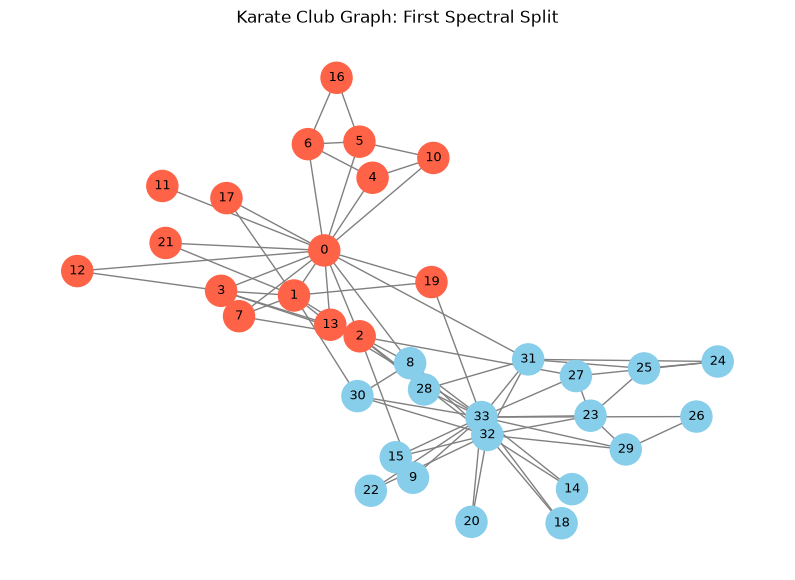

In [49]:
# Fixed layout for consistent visualizations
pos = nx.spring_layout(G, seed=42)

node_colors = []
for node in G.nodes():
    if node in community_1:
        node_colors.append("tomato")
    else:
        node_colors.append("skyblue")

plt.figure(figsize=(10, 7))
nx.draw_networkx(
    G,
    pos=pos,
    node_color=node_colors,
    with_labels=True,
    node_size=500,
    font_size=9,
    edge_color="gray"
)

plt.title("Karate Club Graph: First Spectral Split")
plt.axis("off")
plt.show()

In [50]:
s = np.where(u_1 >= 0, 1, -1)

Q = (s @ B @ s) / (4 * m)

print("Modularity score Q:", Q)

Modularity score Q: 0.37146614069691


In [51]:
def recursive_bisection(B, nodes, m, depth=0, tol=1e-10):
    if len(nodes) < 2:
        return [nodes]

    # Generalized modularity matrix for subgraph C (Newman 2006)
    B_C = B[np.ix_(nodes, nodes)]
    B_C = B_C - np.diag(B_C.sum(axis=1))

    eigenvalues, eigenvectors = np.linalg.eigh(B_C)
    idx = np.argmax(eigenvalues)

    lambda_C = eigenvalues[idx]
    u_C = eigenvectors[:, idx]

    print(
        f"Depth {depth}: {len(nodes)} nodes, "
        f"leading eigenvalue = {lambda_C:.6f}"
    )

    if lambda_C <= tol:
        print("  Stop: leading eigenvalue is nonpositive.")
        return [nodes]

    s = np.where(u_C > 0, 1, -1)
    delta_Q = (s @ B_C @ s) / (4 * m)

    if delta_Q <= tol:
        print(f"  Stop: modularity gain delta_Q = {delta_Q:.6f} <= 0.")
        return [nodes]

    group_1 = [nodes[i] for i in range(len(nodes)) if s[i] == 1]
    group_2 = [nodes[i] for i in range(len(nodes)) if s[i] == -1]

    if not group_1 or not group_2:
        print("  Stop: split produced an empty group.")
        return [nodes]

    print(
        f"  Split into groups of {len(group_1)} and {len(group_2)} nodes "
        f"(delta_Q = {delta_Q:.6f})."
    )

    return (
        recursive_bisection(B, group_1, m, depth + 1, tol)
        + recursive_bisection(B, group_2, m, depth + 1, tol)
    )

In [52]:
# Find the leading eigenvector of the original modularity matrix B
eigenvalues, eigenvectors = np.linalg.eigh(B)

idx = np.argmax(eigenvalues)
lambda_1 = eigenvalues[idx]
u_1 = eigenvectors[:, idx]

print("Leading eigenvalue:", lambda_1)

# Divide nodes according to the signs of the eigenvector
community_1 = [
    i for i in range(len(u_1)) if u_1[i] >= 0
]

community_2 = [
    i for i in range(len(u_1)) if u_1[i] < 0
]

print("Community 1:", community_1)
print("Community 2:", community_2)

Leading eigenvalue: 4.977080225729886
Community 1: [0, 1, 2, 3, 4, 5, 6, 7, 10, 11, 12, 13, 16, 17, 19, 21]
Community 2: [8, 9, 14, 15, 18, 20, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33]


In [53]:
initial_communities = [community_1, community_2]

final_communities = []

for community in initial_communities:
    final_communities.extend(
        recursive_bisection(B, community ,m)
    )

print("\nFinal number of communities:", len(final_communities))

for i, community in enumerate(final_communities, start=1):
    print(f"Community {i}: {len(community)} nodes")
    print(sorted(community))

Depth 0: 16 nodes, leading eigenvalue = 1.178538
  Split into groups of 7 and 9 nodes (delta_Q = 0.001233).
Depth 1: 7 nodes, leading eigenvalue = -0.000000
  Stop: leading eigenvalue is nonpositive.
Depth 1: 9 nodes, leading eigenvalue = 0.060191
  Stop: modularity gain delta_Q = -0.015779 <= 0.
Depth 0: 18 nodes, leading eigenvalue = 0.859415
  Split into groups of 12 and 6 nodes (delta_Q = 0.020710).
Depth 1: 12 nodes, leading eigenvalue = 0.000000
  Stop: leading eigenvalue is nonpositive.
Depth 1: 6 nodes, leading eigenvalue = 0.000000
  Stop: leading eigenvalue is nonpositive.

Final number of communities: 4
Community 1: 7 nodes
[0, 4, 5, 6, 10, 11, 16]
Community 2: 9 nodes
[1, 2, 3, 7, 12, 13, 17, 19, 21]
Community 3: 12 nodes
[8, 9, 14, 15, 18, 20, 22, 26, 29, 30, 32, 33]
Community 4: 6 nodes
[23, 24, 25, 27, 28, 31]


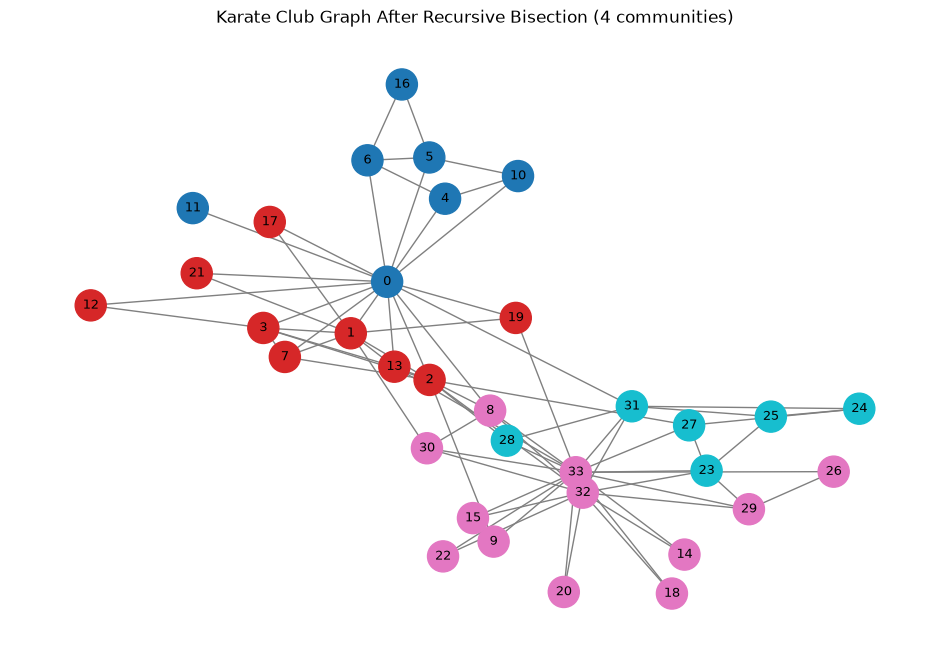

In [54]:
colors = plt.cm.tab10(
    np.linspace(0, 1, len(final_communities))
)

node_color_map = {}

for i, community in enumerate(final_communities):
    for node in community:
        node_color_map[node] = colors[i]

plt.figure(figsize=(12, 8))

nx.draw_networkx(
    G,
    pos=pos,
    node_color=[node_color_map[node] for node in G.nodes()],
    with_labels=True,
    node_size=500,
    font_size=9,
    edge_color="gray"
)

plt.title(
    f"Karate Club Graph After Recursive Bisection "
    f"({len(final_communities)} communities)"
)
plt.axis("off")
plt.show()

In [55]:
Q_final = sum(
    B[np.ix_(community, community)].sum()
    for community in final_communities
) / (2 * m)

print("Final modularity Q =", Q_final)

Final modularity Q = 0.3934089414858646


In [56]:
degree_centrality = nx.degree_centrality(G)
betweenness_centrality = nx.betweenness_centrality(G)
closeness_centrality = nx.closeness_centrality(G)
clustering_coefficient = nx.clustering(G)

metrics = {
    "Degree Centrality": degree_centrality,
    "Betweenness Centrality": betweenness_centrality,
    "Closeness Centrality": closeness_centrality,
    "Clustering Coefficient": clustering_coefficient
}

for name, values in metrics.items():
    top_nodes = sorted(values.items(), key=lambda item: item[1], reverse=True)[:5]
    print(f"\nTop 5 nodes by {name}:")
    for node, value in top_nodes:
        print(f"Node {node}: {value:.4f}")


Top 5 nodes by Degree Centrality:
Node 33: 0.5152
Node 0: 0.4848
Node 32: 0.3636
Node 2: 0.3030
Node 1: 0.2727

Top 5 nodes by Betweenness Centrality:
Node 0: 0.4376
Node 33: 0.3041
Node 32: 0.1452
Node 2: 0.1437
Node 31: 0.1383

Top 5 nodes by Closeness Centrality:
Node 0: 0.5690
Node 2: 0.5593
Node 33: 0.5500
Node 31: 0.5410
Node 8: 0.5156

Top 5 nodes by Clustering Coefficient:
Node 7: 1.0000
Node 12: 1.0000
Node 14: 1.0000
Node 15: 1.0000
Node 16: 1.0000


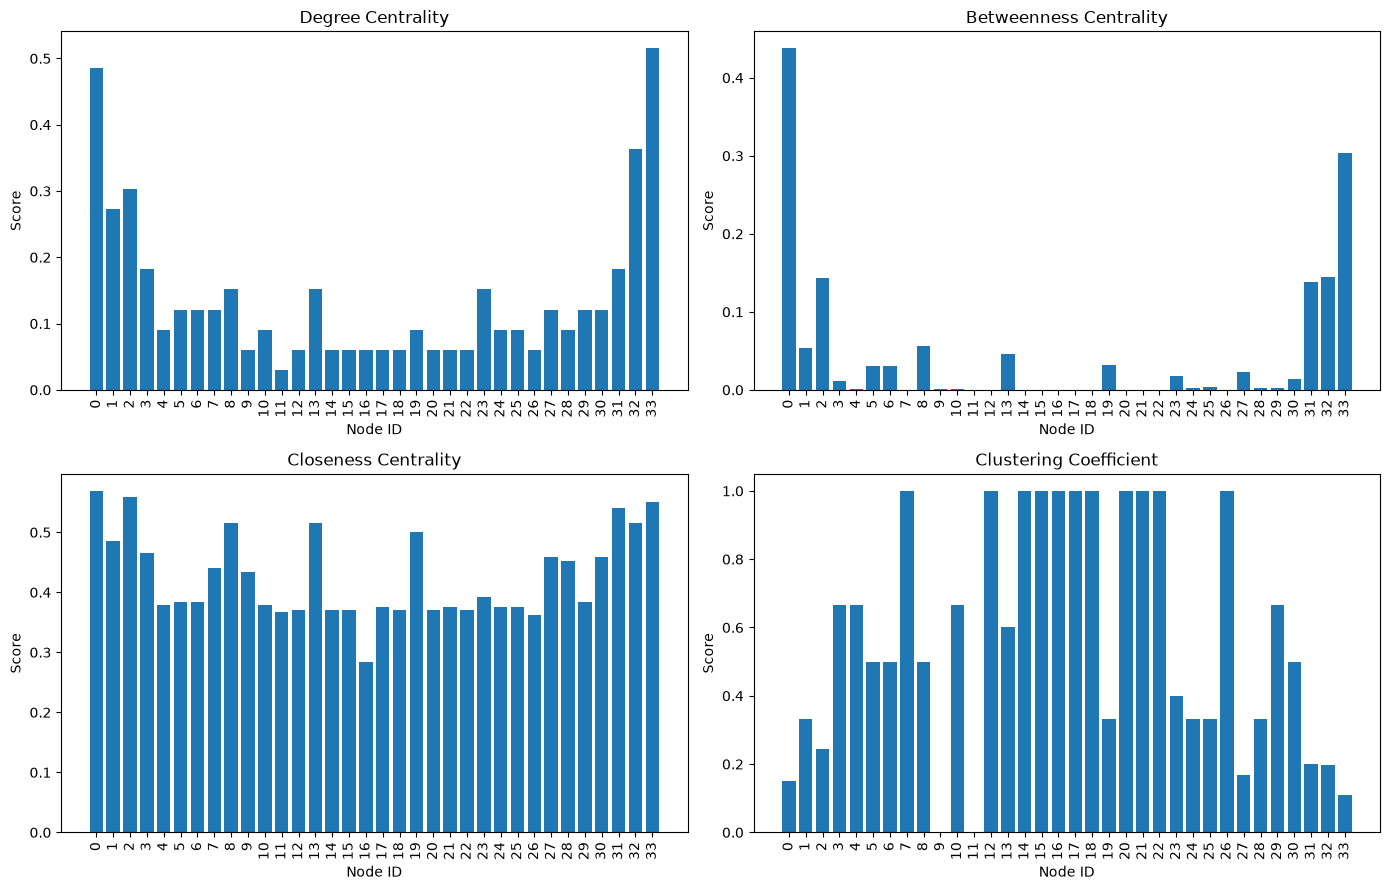

In [57]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for ax, (name, values) in zip(axes.flat, metrics.items()):
    nodes = list(G.nodes())
    scores = [values[node] for node in nodes]

    ax.bar(nodes, scores)
    ax.set_title(name)
    ax.set_xlabel("Node ID")
    ax.set_ylabel("Score")
    ax.set_xticks(nodes)
    ax.tick_params(axis="x", labelrotation=90)

plt.tight_layout()
plt.show()

In [58]:
# Record the partition at each stage of recursive bisection

partition_history = [
    [list(G.nodes())],

    [community_1, community_2],

    [
        [0, 1, 2, 3, 7, 12, 13, 17, 19, 21],
        [4, 5, 6, 10, 11, 16],
        [24, 25, 27, 28, 31],
        [8, 9, 14, 15, 18, 20, 22, 23, 26, 29, 30, 32, 33]
    ],

    final_communities
]

metric_history = {
    "Degree Centrality": [],
    "Betweenness Centrality": [],
    "Closeness Centrality": [],
    "Clustering Coefficient": []
}

for partition in partition_history:
    values = {
        name: {} for name in metric_history
    }

    for community in partition:
        subgraph = G.subgraph(community)

        community_metrics = {
            "Degree Centrality": nx.degree_centrality(subgraph),
            "Betweenness Centrality": nx.betweenness_centrality(subgraph),
            "Closeness Centrality": nx.closeness_centrality(subgraph),
            "Clustering Coefficient": nx.clustering(subgraph)
        }

        for name, scores in community_metrics.items():
            values[name].update(scores)

    for name in metric_history:
        metric_history[name].append(values[name])

print("Metric values stored for", len(partition_history), "iterations.")

Metric values stored for 4 iterations.


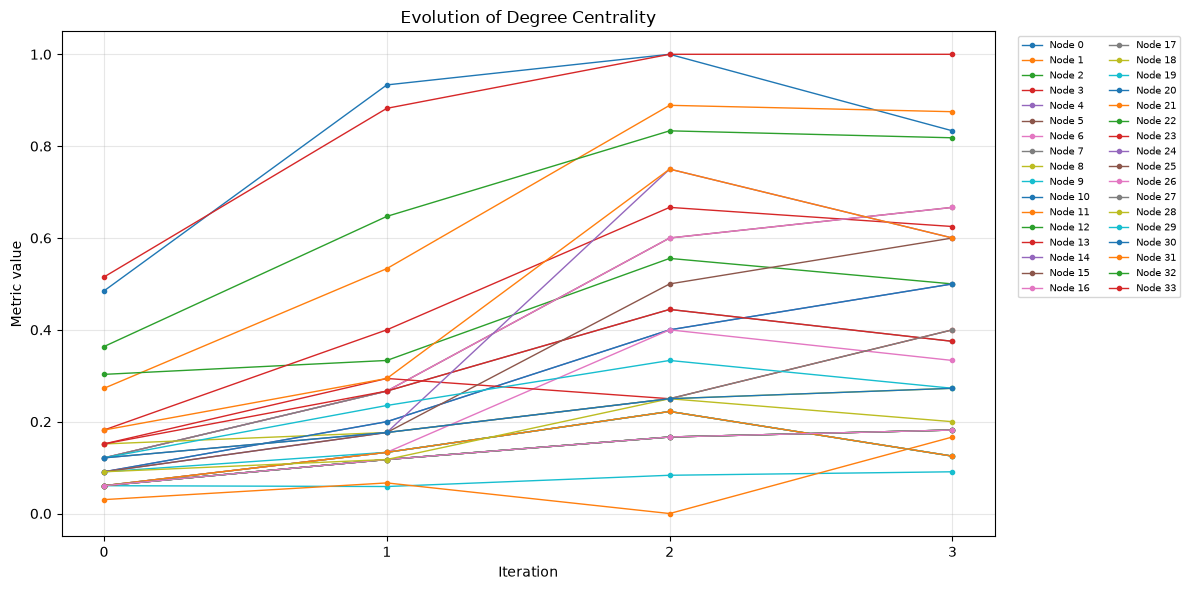

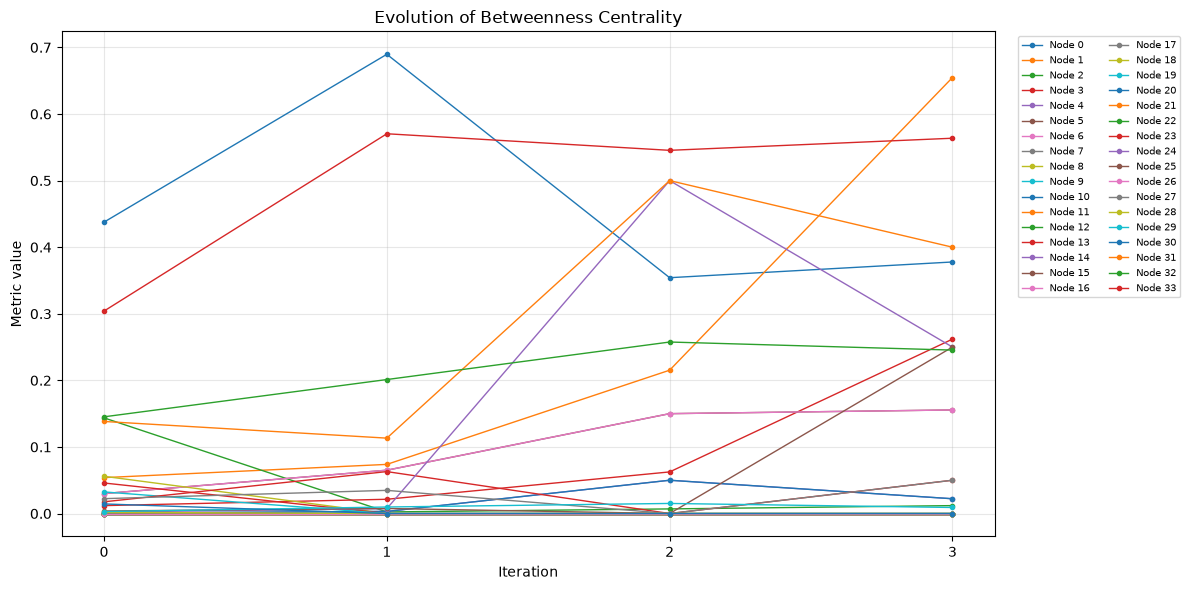

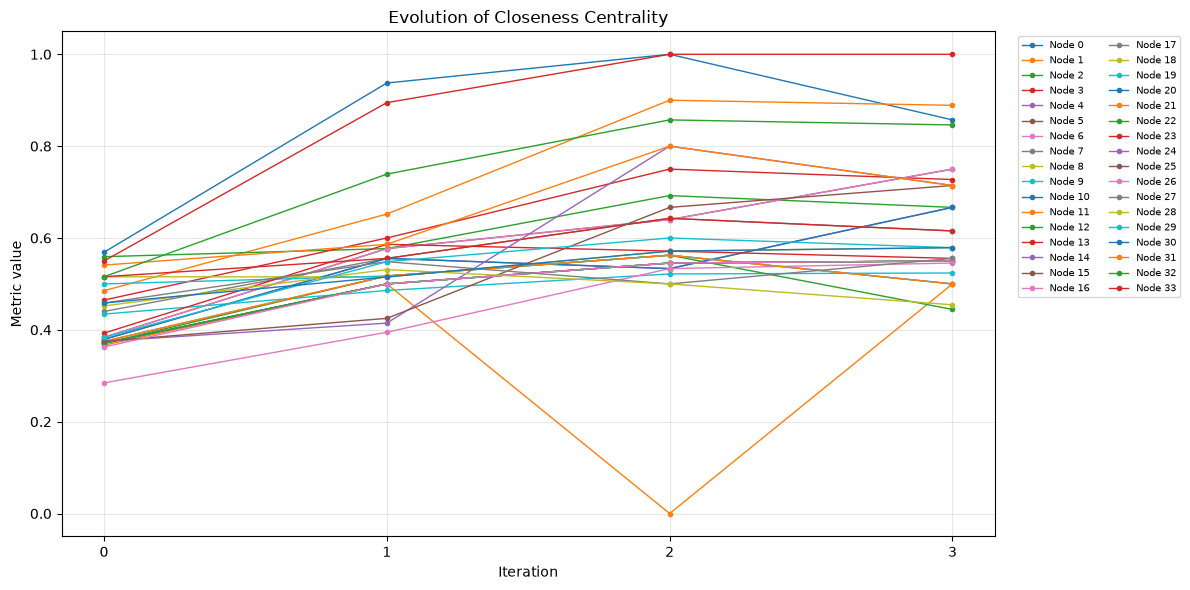

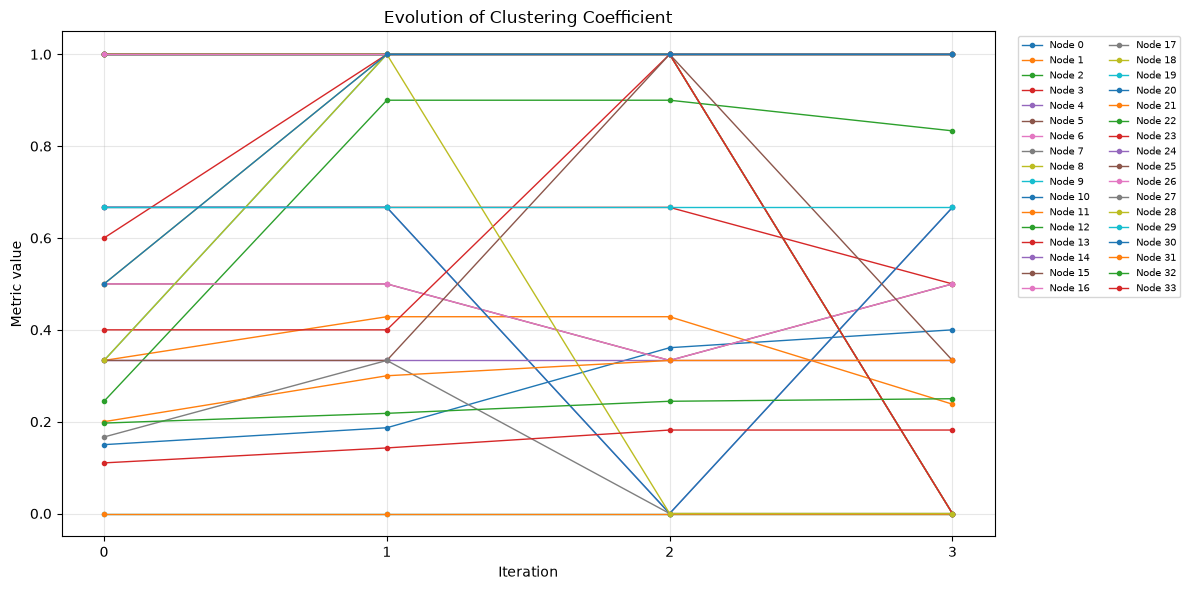

In [59]:
for name, history in metric_history.items():
    plt.figure(figsize=(12, 6))

    for node in G.nodes():
        scores = [
            iteration[node] for iteration in history
        ]
        plt.plot(
            range(len(history)),
            scores,
            marker="o",
            markersize=3,
            linewidth=1,
            label=f"Node {node}"
        )

    plt.title(f"Evolution of {name}")
    plt.xlabel("Iteration")
    plt.ylabel("Metric value")
    plt.xticks(range(len(history)))
    plt.grid(True, alpha=0.3)
    plt.legend(
        bbox_to_anchor=(1.02, 1),
        loc="upper left",
        ncol=2,
        fontsize=7
    )
    plt.tight_layout()
    plt.show()